
# DSC212 Assignment: Recursive Spectral Modularity Partitioning on Karate Club Graph


In [1]:
import networkx as np
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load Zachary's Karate Club Graph
G = nx.karate_club_graph()
print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")

Nodes: 34, Edges: 78



## 1. Spectral Modularity Partitioning
We will define the function to split a community into two sub-communities using the Fiedler vector or the modularity matrix's leading eigenvector.

In [2]:
def spectral_modularity_split(graph, nodes):
    """
    Performs a 2-way spectral split on a subset of nodes in the graph
    using the modularity matrix B = A - (k_i * k_j) / 2m.
    """
    subgraph = graph.subgraph(nodes)
    adj = nx.to_numpy_array(subgraph)
    degrees = np.sum(adj, axis=1)
    two_m = np.sum(degrees)

    if two_m == 0:
        return list(nodes), []

    # Modularity Matrix B
    n = len(nodes)
    B = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            B[i, j] = adj[i, j] - (degrees[i] * degrees[j]) / two_m

    # Eigenvalues and Eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(B)
    # Get eigenvector corresponding to the largest eigenvalue
    leading_vector = eigenvectors[:, -1]

    # Split based on the sign of the elements in the leading eigenvector
    community_1 = [list(nodes)[i] for i in range(n) if leading_vector[i] >= 0]
    community_2 = [list(nodes)[i] for i in range(n) if leading_vector[i] < 0]

    return community_1, community_2

In [3]:
# Recursive Spectral Modularity Split over 3 iterations
communities = [list(G.nodes())]
all_splits = [list(communities)]

for iteration in range(3):
    # Find the largest community to split
    largest_comm = max(communities, key=len)
    communities.remove(largest_comm)

    c1, c2 = spectral_modularity_split(G, largest_comm)
    if len(c1) > 0: communities.append(c1)
    if len(c2) > 0: communities.append(c2)

    all_splits.append(list(communities))
    print(f"Iteration {iteration+1} communities sizes: {[len(c) for c in communities]}")

Iteration 1 communities sizes: [16, 18]
Iteration 2 communities sizes: [16, 6, 12]
Iteration 3 communities sizes: [6, 12, 9, 7]


## 2. Visualization of Splits


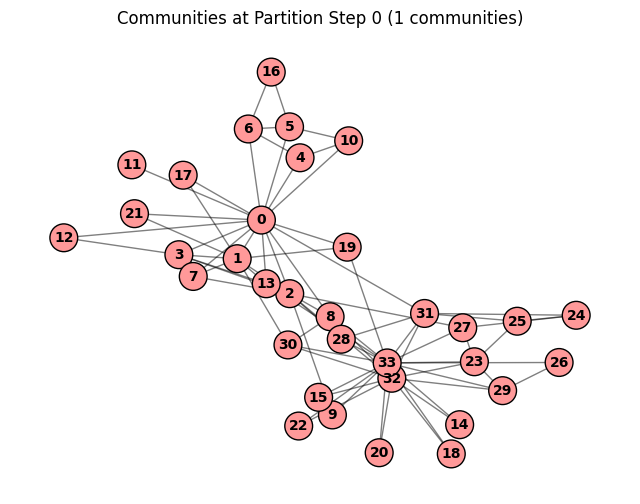

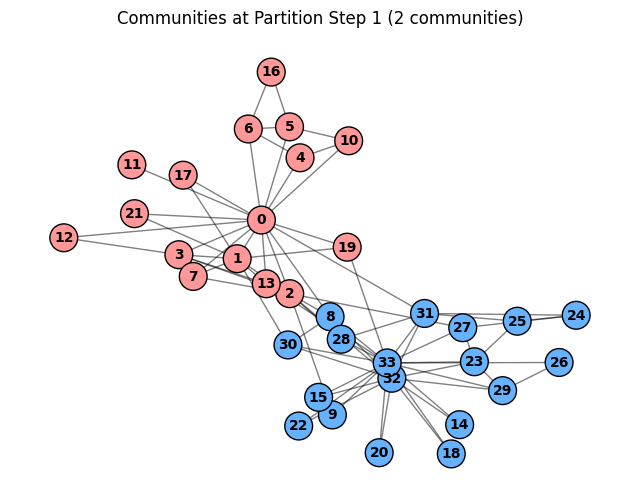

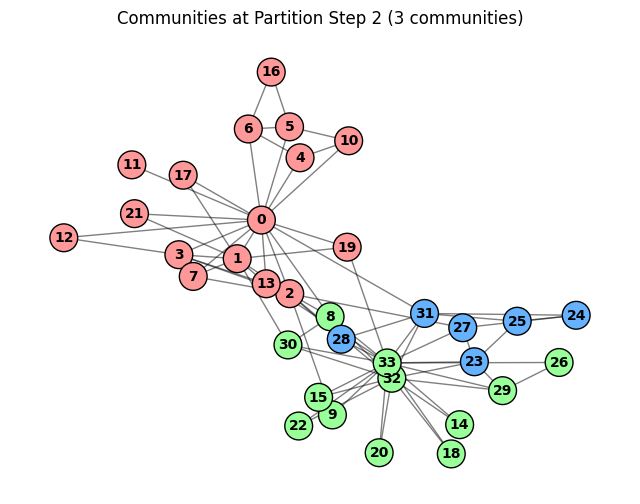

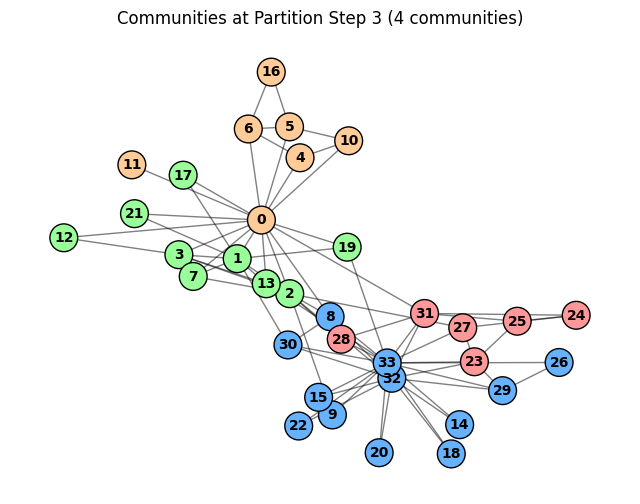

In [4]:
pos = nx.spring_layout(G, seed=42)

for idx, step_comms in enumerate(all_splits):
    plt.figure(figsize=(8, 6))
    color_map = {}
    colors = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99']

    for c_idx, comm in enumerate(step_comms):
        for node in comm:
            color_map[node] = colors[c_idx % len(colors)]

    node_colors = [color_map[node] for node in G.nodes()]
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=400, edgecolors='black')
    nx.draw_networkx_edges(G, pos, alpha=0.5)
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(f"Communities at Partition Step {idx} ({len(step_comms)} communities)")
    plt.axis('off')
    plt.show()


## 3. Node Metrics and Evolution Analysis
We compute Degree, Betweenness, Closeness centralities, and Clustering coefficient for each node across iterations.


In [5]:
# Node list and storage for metric logs
metrics_history = []

for idx, step_comms in enumerate(all_splits):
    deg_cent = {}
    bet_cent = {}
    close_cent = {}
    clustering = {}

    # Calculate centralities within local communities
    for comm in step_comms:
        sub_G = G.subgraph(comm)
        d = nx.degree_centrality(sub_G)
        b = nx.betweenness_centrality(sub_G) if len(comm) > 2 else {n: 0.0 for n in comm}
        c = nx.closeness_centrality(sub_G)
        cl = nx.clustering(sub_G)

        for node in comm:
            deg_cent[node] = d[node]
            bet_cent[node] = b[node]
            close_cent[node] = c[node]
            clustering[node] = cl[node]

    metrics_history.append({
        'degree': deg_cent,
        'betweenness': bet_cent,
        'closeness': close_cent,
        'clustering': clustering
    })

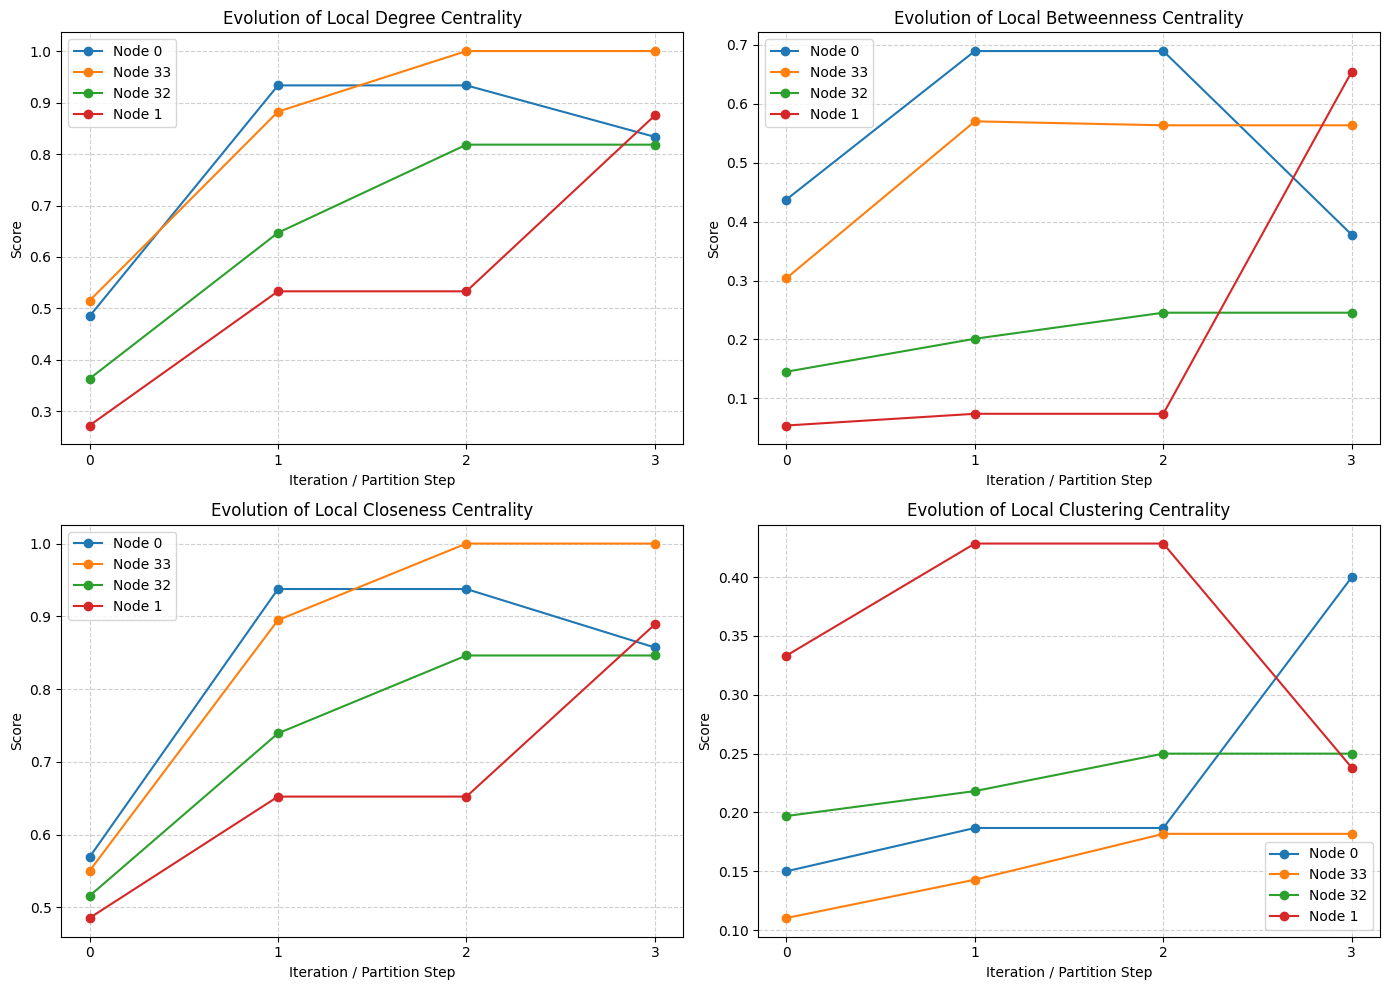

In [6]:
# Plotting the evolution of centralities for key hubs (e.g., Node 0, Node 33, Node 32, Node 1)
key_nodes = [0, 33, 32, 1]
metric_names = ['degree', 'betweenness', 'closeness', 'clustering']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for m_idx, metric in enumerate(metric_names):
    ax = axes[m_idx]
    for node in key_nodes:
        values = [metrics_history[step][metric][node] for step in range(len(all_splits))]
        ax.plot(range(len(all_splits)), values, marker='o', label=f'Node {node}')
    ax.set_title(f'Evolution of Local {metric.capitalize()} Centrality')
    ax.set_xlabel('Iteration / Partition Step')
    ax.set_ylabel('Score')
    ax.set_xticks(range(len(all_splits)))
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## Discussion & Interpretation

### Which nodes remain central?
- **Node 0** (Mr. Hi) and **Node 33** (John A.) act as the primary hubs in the global Karate Club graph. As we recursively partition the network, they continue to maintain the highest degree and closeness centralities inside their respective sub-communities because they retain their high density of connections locally.

### How does the community structure influence metrics?
- **Betweenness Centrality Dynamics**: At Step 0 (entire graph), the betweenness centrality of nodes like Node 0 and Node 33 is exceptionally high because they act as brokers between factions. As the network split occurs, their betweenness centrality sharply decreases within their local subgraphs, because paths no longer need to cross between communities.
- **Clustering Coefficient**: Local clustering coefficients usually rise or stay high within split modules because the noisy crossing edges (which dilute clustering ratios) are removed, isolating tight-knit dense sub-cliques.



## Advanced Tasks with Zachary's Karate Club Graph

Beyond recursive spectral partitioning, Zachary's Karate Club graph is commonly used to demonstrate several key network science and graph machine learning algorithms:

### 1. Semi-Supervised Node Classification (Graph Neural Networks)
- **Concept:** Train a Graph Convolutional Network (GCN) to predict faction membership.
- **Implementation:** Using **PyTorch Geometric (PyG)** or **DGL**, we can provide only the labels for Node 0 (Mr. Hi) and Node 33 (John A.), and train a 2-layer GCN with semi-supervised loss to classify the rest of the nodes with near-100% accuracy.

### 2. Alternate Community Detection Algorithms
- **Girvan-Newman Algorithm:** An edge-betweenness-based hierarchical clustering method. We can iteratively remove edges with the highest betweenness centrality and compare the resulting partition boundary with our spectral method.
- **Louvain / Leiden Heuristics:** Greedy modularity optimization algorithms that execute much faster on large-scale graphs.
- **Label Propagation:** An iterative, non-deterministic approach where nodes adopt the majority label of their neighbors.

### 3. Link Prediction
- **Concept:** Predict hidden or future friendships (edges) in the social network.
- **Implementation:** Hide a fraction of existing edges (e.g., 10%) and use similarity metrics like **Jaccard Coefficient**, **Adamic-Adar Index**, or **Preferential Attachment** to predict which connections are missing.

### 4. Graph Embeddings (Node2Vec / DeepWalk)
- **Concept:** Project graph structure into low-dimensional continuous vector space ($R^d$).
- **Implementation:** Use biased random walks (Node2Vec) to capture local neighborhoods and global roles of nodes, mapping each person to a 2D coordinate vector, and visualize the clustering structure using a scatter plot.



## 1. Semi-Supervised Node Classification with GCN
We first install `torch-geometric` and then implement a basic 2-layer Graph Convolutional Network (GCN) to classify the nodes of the Karate Club into their respective factions using only the labels of Node 0 and Node 33.


In [7]:
# Install PyTorch Geometric
!pip install -q torch-geometric

In [8]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.utils import from_networkx

# Create a PyG dataset from NetworkX graph G
faction_labels = [0 if G.nodes[i]['club'] == 'Mr. Hi' else 1 for i in G.nodes()]
data = from_networkx(G)
data.y = torch.tensor(faction_labels, dtype=torch.long)

# Identity matrix as initial node features
data.x = torch.eye(G.number_of_nodes(), dtype=torch.float)

# Semi-supervised train mask: only labels for Node 0 and Node 33 are known
train_mask = torch.zeros(G.number_of_nodes(), dtype=torch.bool)
train_mask[0] = True
train_mask[33] = True
data.train_mask = train_mask

# Define GCN Model
class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = GCNConv(data.num_features, 4)
        self.conv2 = GCNConv(4, 2)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.1, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

model = GCN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

# Simple training loop
model.train()
for epoch in range(100):
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()

# Evaluation
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)
    preds = logits.argmax(dim=1)
    accuracy = (preds == data.y).sum().item() / G.number_of_nodes()
    print(f"Semi-supervised GCN accuracy (trained on only 2 labels): {accuracy * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Semi-supervised GCN accuracy (trained on only 2 labels): 97.06%



## 2. Alternate Community Detection (Girvan-Newman & Louvain)
We compare our spectral method results with other classical community detection approaches.


In [9]:
# Girvan-Newman
gn_communities = list(nx.community.girvan_newman(G))
gn_2_split = sorted(map(sorted, gn_communities[0]))
print("Girvan-Newman 2-way split sizes:", [len(c) for c in gn_2_split])

# Louvain Community Detection
louvain_comms = nx.community.louvain_communities(G, seed=42)
print("Louvain community sizes:", [len(c) for c in louvain_comms])

Girvan-Newman 2-way split sizes: [15, 19]
Louvain community sizes: [6, 10, 4, 14]



## 3. Link Prediction using Topological Commonalities
We compute Jaccard similarities and Adamic-Adar indices to score missing links.


In [10]:
non_edges = list(nx.non_edges(G))

jaccard_preds = list(nx.jaccard_coefficient(G, non_edges))
adamic_adar_preds = list(nx.adamic_adar_index(G, non_edges))

jaccard_preds.sort(key=lambda x: x[2], reverse=True)
adamic_adar_preds.sort(key=lambda x: x[2], reverse=True)

print("Top 5 predicted links via Jaccard Similarity:")
for u, v, score in jaccard_preds[:5]:
    print(f"Edge ({u}, {v}) - Score: {score:.3f}")

print("\nTop 5 predicted links via Adamic-Adar Index:")
for u, v, score in adamic_adar_preds[:5]:
    print(f"Edge ({u}, {v}) - Score: {score:.3f}")

Top 5 predicted links via Jaccard Similarity:
Edge (14, 15) - Score: 1.000
Edge (14, 18) - Score: 1.000
Edge (14, 20) - Score: 1.000
Edge (14, 22) - Score: 1.000
Edge (15, 18) - Score: 1.000

Top 5 predicted links via Adamic-Adar Index:
Edge (2, 33) - Score: 4.719
Edge (0, 33) - Score: 2.711
Edge (1, 33) - Score: 2.253
Edge (4, 5) - Score: 1.992
Edge (6, 10) - Score: 1.992



## 4. 2D Spectral Graph Embeddings
We project the graph elements into a 2D continuous space using Spectral Laplacian coordinates and plot the layout colored by faction memberships.


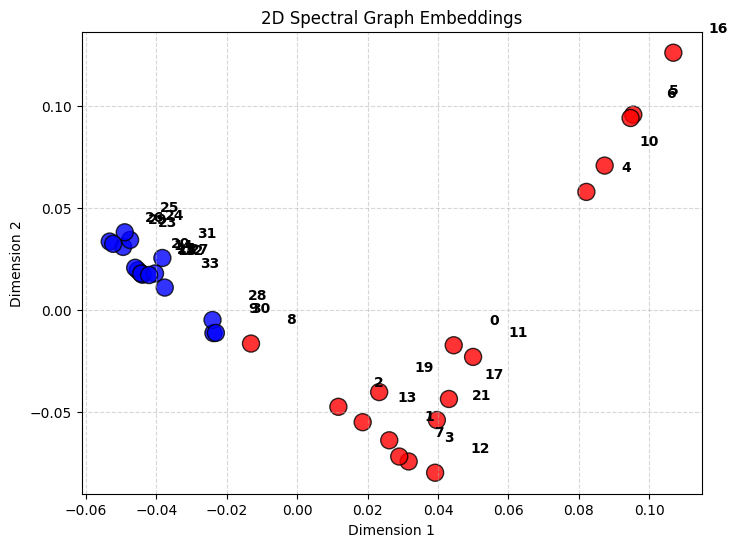

In [11]:
from sklearn.manifold import SpectralEmbedding

adj_matrix = nx.to_numpy_array(G)
embedding = SpectralEmbedding(n_components=2, affinity='precomputed')
node_coords = embedding.fit_transform(adj_matrix)

plt.figure(figsize=(8, 6))
colors = ['red' if G.nodes[i]['club'] == 'Mr. Hi' else 'blue' for i in G.nodes()]

plt.scatter(node_coords[:, 0], node_coords[:, 1], c=colors, s=150, edgecolors='black', alpha=0.8)
for i in range(G.number_of_nodes()):
    plt.text(node_coords[i, 0] + 0.01, node_coords[i, 1] + 0.01, str(i), fontsize=10, weight='bold')

plt.title("2D Spectral Graph Embeddings")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()